# Step 15 — Does feature bagging actually prevent expert collapse?

Notebook 01 measured that trained experts stay diverse (mean pairwise cosine similarity +0.108,
far from the 1.0 of total collapse). That shows the experts don't collapse **with** feature
bagging — but never showed they **would** collapse without it. This notebook runs that missing
control.

### Design
* Two arms, identical except for one setting:
  * **with bagging** — `feature_frac=0.7`: each of the 16 experts sees its own random 70% of the columns
  * **without bagging** — `feature_frac=1.0`: every expert sees every column
* Same architecture as notebooks 01/02 (mean-pool, small head, no embedding), same 5 seeds,
  lr 1e-3, batch 512, up to 200 epochs with early stopping (patience 20).
* Datasets (exact published splits): **California Housing** (8 features, regression) and
  **Higgs Small** (28 features, binary).
* Expert similarity measured on the validation set, **before and after** training, per sample
  then averaged (`WeakLearnerEnsemble.diversity_stats`'s definition). 1.0 = every expert
  produces the same representation (total collapse); 0 = unrelated.

## 0. Setup

In [1]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")
PROJECT_DIR = os.getcwd(); sys.path.insert(0, PROJECT_DIR)
os.environ["PYTHONPATH"] = PROJECT_DIR + os.pathsep + os.environ.get("PYTHONPATH", "")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed

import benchmarks, benchmarks_rtdl
from training import get_device
from plotting import apply_style, role_color, INK, INK_SECONDARY, _strip_axes

DEVICE = get_device()
KEYS      = os.environ.get("SRP_KEYS", "CA,HI").split(",")
SEEDS     = tuple(range(int(os.environ.get("SRP_SEEDS", "5"))))
EPOCHS    = int(os.environ.get("SRP_EPOCHS", "200"))
PATIENCE  = int(os.environ.get("SRP_PATIENCE", "20"))
SUBSAMPLE = int(os.environ.get("SRP_SUBSAMPLE", "0")) or None
FRACS     = {"with bagging (70% of columns)": 0.7, "without bagging (all columns)": 1.0}

ENS_KW   = dict(num_learners=16, hidden_dim=16, embed_dim=32, depth=1, dropout=0.1)
TRAIN_KW = dict(epochs=EPOCHS, patience=PATIENCE, lr=1e-3, batch_size=512, weight_decay=1e-4)
LOADER = {"CA": benchmarks_rtdl, "HI": benchmarks}

THREADS_PER_JOB = 2
N_JOBS = int(os.environ.get("SRP_JOBS", "0")) or (
    3 if DEVICE.type == "cuda" else max(1, min(8, (os.cpu_count() or 2) // THREADS_PER_JOB)))
FIG_DIR = os.path.join(os.path.dirname(PROJECT_DIR), "figures")
apply_style()
print(f"device {DEVICE} | keys {KEYS} | seeds {len(SEEDS)} | epochs<={EPOCHS} | {N_JOBS} workers"
      + ("  | SMOKE TEST" if SUBSAMPLE else ""))

device cpu | keys ['CA', 'HI'] | seeds 5 | epochs<=500 | 8 workers


## 1. Data

In [2]:
DATA, ARRAYS = {}, {}
for k in KEYS:
    d = LOADER[k].load_benchmark(k)
    a = d.arrays()
    if SUBSAMPLE:
        n = SUBSAMPLE
        a = {"Xtr": a["Xtr"][:n], "ytr": a["ytr"][:n], "Xva": a["Xva"][:n // 2], "yva": a["yva"][:n // 2],
             "Xte": a["Xte"][:n], "yte": a["yte"][:n]}
    DATA[k], ARRAYS[k] = d, a
    print(d.summary())
HIB = {k: LOADER[k].higher_is_better(k) for k in KEYS}

CA California Housing regression features=  8 train=13,209 val=3,303 test=4,128


HI Higgs Small        binary     features= 28 train=62,751 val=15,688 test=19,610  classes=2


## 2. Train both arms, measure expert similarity before and after

In [3]:
def run_one(key, frac, seed, arrays, task, output_dim, n_features, y_std,
            ens_kw, train_kw, device_str, project_dir, threads):
    import sys, time
    if project_dir not in sys.path: sys.path.insert(0, project_dir)
    import numpy as np, torch
    from weak_learners import WeakLearnerConfig
    from model import make_arm
    from training import train_model, evaluate, to_tensors
    torch.set_num_threads(threads)
    data = to_tensors(arrays, device_str)
    Xva = data["Xva"][:4096]
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_arm("meanpool", n_features, WeakLearnerConfig(**ens_kw, feature_frac=frac, seed=seed,
                                                             batched=True),
                     task=task, output_dim=output_dim).to(data["Xtr"].device)
    _, before = model.ensemble.diversity_stats(Xva)
    t0 = time.time()
    model, hist = train_model(model, data, seed=seed, **train_kw)
    sim, after = model.ensemble.diversity_stats(Xva)
    test = evaluate(model, data["Xte"], arrays["yte"], task)
    score = test["rmse"] * y_std if task == "regression" else test["acc"]
    return {"key": key, "frac": frac, "seed": seed, "sim_before": before, "sim_after": after,
            "sim_matrix": sim.cpu().numpy(), "score": score, "best_epoch": hist["best_epoch"] + 1,
            "seconds": time.time() - t0}

jobs = [(k, f, s) for k in sorted(KEYS, key=lambda k: k != "HI") for f in FRACS.values() for s in SEEDS]
t0, RES = time.time(), []
for r in Parallel(n_jobs=N_JOBS, return_as="generator")(
        delayed(run_one)(k, f, s, ARRAYS[k], DATA[k].task, DATA[k].output_dim, DATA[k].n_features,
                         DATA[k].y_std, ENS_KW, TRAIN_KW, str(DEVICE), PROJECT_DIR, THREADS_PER_JOB)
        for k, f, s in jobs):
    RES.append(r)
    print(f"  [{len(RES):2d}/{len(jobs)}] {r['key']} feature_frac={r['frac']:.1f} seed {r['seed']}  "
          f"similarity {r['sim_before']:+.3f} -> {r['sim_after']:+.3f}  score {r['score']:.4f}  "
          f"best epoch {r['best_epoch']}  ({r['seconds']/60:.1f} min)  elapsed {(time.time()-t0)/60:.1f} min",
          flush=True)
R = pd.DataFrame([{k: v for k, v in r.items() if k != "sim_matrix"} for r in RES])
print(f"done in {(time.time()-t0)/60:.1f} min")

/home/shayan/Desktop/SRP/v4/training.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return {k: torch.as_tensor(np.ascontiguousarray(v)).to(dev) for k, v in arrays.items()}
/home/shayan/Desktop/SRP/v4/training.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/ten

/home/shayan/Desktop/SRP/v4/training.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return {k: torch.as_tensor(np.ascontiguousarray(v)).to(dev) for k, v in arrays.items()}
/home/shayan/Desktop/SRP/v4/training.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/ten

  [ 1/20] HI feature_frac=0.7 seed 0  similarity +0.004 -> +0.038  score 0.7191  best epoch 43  (2.3 min)  elapsed 2.4 min


  [ 2/20] HI feature_frac=0.7 seed 1  similarity +0.000 -> +0.031  score 0.7175  best epoch 36  (2.1 min)  elapsed 2.4 min


  [ 3/20] HI feature_frac=0.7 seed 2  similarity +0.009 -> +0.030  score 0.7230  best epoch 58  (3.0 min)  elapsed 3.0 min


...

  [17/20] CA feature_frac=1.0 seed 1  similarity -0.011 -> +0.079  score 0.5055  best epoch 243  (1.5 min)  elapsed 6.0 min


  [18/20] CA feature_frac=1.0 seed 2  similarity -0.005 -> +0.088  score 0.4959  best epoch 320  (1.8 min)  elapsed 6.4 min


  [19/20] CA feature_frac=1.0 seed 3  similarity +0.018 -> +0.093  score 0.5006  best epoch 392  (2.0 min)  elapsed 6.7 min


  [20/20] CA feature_frac=1.0 seed 4  similarity -0.012 -> +0.093  score 0.5044  best epoch 428  (2.1 min)  elapsed 7.0 min


done in 7.0 min


## 3. Results

In [4]:
LABEL = {v: k for k, v in FRACS.items()}
rows = []
for k in KEYS:
    for f in FRACS.values():
        x = R[(R.key == k) & (R.frac == f)]
        rows.append({"dataset": DATA[k].label, "arm": LABEL[f],
                     "similarity before": x.sim_before.mean(),
                     "similarity after": x.sim_after.mean(), "± std (after)": x.sim_after.std(),
                     "test score": x.score.mean(), "± std (score)": x.score.std()})
T = pd.DataFrame(rows).set_index(["dataset", "arm"])
print("Expert similarity (1.0 = total collapse) and test score (RMSE for CA, lower better; accuracy for HI)")
display(T.round(4))

rows = []
for k in KEYS:
    w = R[R.key == k].pivot(index="seed", columns="frac")
    d_sim = (w["sim_after"][1.0] - w["sim_after"][0.7]).values
    p_sim = stats.ttest_rel(w["sim_after"][1.0], w["sim_after"][0.7]).pvalue
    sign = 1.0 if HIB[k] else -1.0
    d_sc = sign * (w["score"][0.7] - w["score"][1.0]).values
    p_sc = stats.ttest_rel(w["score"][0.7], w["score"][1.0]).pvalue
    rows.append({"dataset": DATA[k].label,
                 "similarity: without − with bagging": d_sim.mean(), "p (similarity)": p_sim,
                 "accuracy advantage of bagging": d_sc.mean(), "p (score)": p_sc})
PAIRED = pd.DataFrame(rows).set_index("dataset")
print("\nPaired over seeds (same seed = same initial experts apart from the column subsets)")
display(PAIRED.round(4))

Expert similarity (1.0 = total collapse) and test score (RMSE for CA, lower better; accuracy for HI)


similarity before  \
dataset            arm                                                
California Housing with bagging (70% of columns)             0.0053   
                   without bagging (all columns)            -0.0041   
Higgs Small        with bagging (70% of columns)             0.0050   
                   without bagging (all columns)             0.0019   

                                                  similarity after  \
dataset            arm                                               
California Housing with bagging (70% of columns)            0.0722   
                   without bagging (all columns)            0.0911   
Higgs Small        with bagging (70% of columns)            0.0363   
                   without bagging (all columns)            0.0514   

                                                  ± std (after)  test score  \
dataset            arm                                                        
California Housing with bagging (70% of columns)         0.0130      0.5012   
                   without bagging (all columns)         0.0087      0.5018   
Higgs Small        with bagging (70% of columns)         0.0060      0.7194   
                   without bagging (all columns)         0.0070      0.7157   

                                                  ± std (score)  
dataset            arm                                           
California Housing with bagging (70% of columns)         0.0010  
                   without bagging (all columns)         0.0038  
Higgs Small        with bagging (70% of columns)         0.0021  
                   without bagging (all columns)         0.0021


Paired over seeds (same seed = same initial experts apart from the column subsets)


,similarity: without − with bagging,p (similarity),accuracy advantage of bagging,p (score)
dataset,,,,
California Housing,0.0188,0.0560,0.0006,0.7099
Higgs Small,0.0152,0.0189,0.0036,0.0544


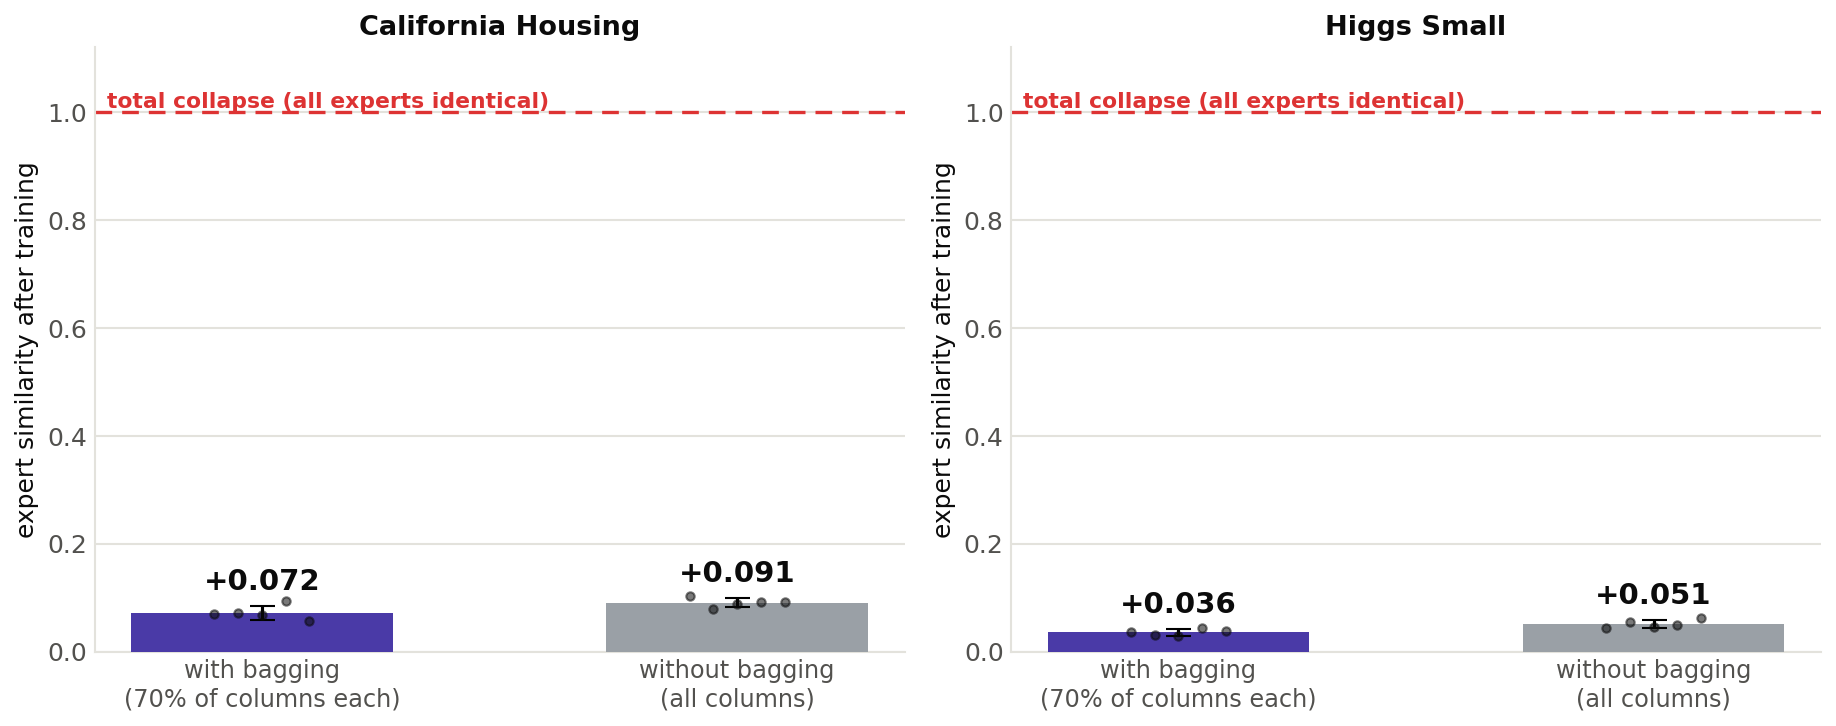

In [5]:
fig, axes = plt.subplots(1, len(KEYS), figsize=(6.2 * len(KEYS), 5.0))
axes = np.atleast_1d(axes)
colors = {0.7: role_color("meanpool"), 1.0: role_color("PlainMLP")}
for ax, k in zip(axes, KEYS):
    for i, f in enumerate(FRACS.values()):
        x = R[(R.key == k) & (R.frac == f)]
        m, s = x.sim_after.mean(), x.sim_after.std()
        ax.bar(i, m, yerr=s, capsize=6, width=0.55, color=colors[f], zorder=3)
        ax.scatter(np.full(len(x), i) + np.linspace(-0.1, 0.1, len(x)), x.sim_after, s=16,
                   color=INK, alpha=0.55, zorder=4)
        ax.text(i, m + (s if s == s else 0) + 0.03, f"{m:+.3f}", ha="center", fontsize=14,
                fontweight="bold", color=INK)
    ax.axhline(1.0, color="#d33", linestyle=(0, (5, 3)), linewidth=1.6)
    ax.text(0.015, 1.0, "total collapse (all experts identical)", transform=ax.get_yaxis_transform(),
            color="#d33", fontsize=10.5, fontweight="bold", va="bottom", ha="left")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["with bagging\n(70% of columns each)",
                                              "without bagging\n(all columns)"], fontsize=11.5)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("expert similarity after training")
    ax.set_title(DATA[k].label, fontweight="bold")
    _strip_axes(ax)
plt.tight_layout()
if not SUBSAMPLE:
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIG_DIR, "feature_bagging_collapse.pdf"), dpi=200)
    fig.savefig(os.path.join(FIG_DIR, "feature_bagging_collapse.png"), dpi=200)
plt.show()

## 4. Findings

In [6]:
sep = "=" * 92
print(sep); print("FINDINGS -- does feature bagging prevent expert collapse?"); print(sep)
for k in KEYS:
    w = T.loc[DATA[k].label]
    p = PAIRED.loc[DATA[k].label]
    a_with = w.loc[LABEL[0.7], "similarity after"]; a_without = w.loc[LABEL[1.0], "similarity after"]
    print(f"\n{DATA[k].label}:")
    print(f"   similarity after training: with bagging {a_with:+.3f} | without {a_without:+.3f}"
          f"   (difference {a_without - a_with:+.3f}, p={p['p (similarity)']:.3f})")
    print(f"   test score: with bagging {w.loc[LABEL[0.7], 'test score']:.4f} | "
          f"without {w.loc[LABEL[1.0], 'test score']:.4f}   (p={p['p (score)']:.3f})")
    if a_without > 0.5:
        print("   -> WITHOUT bagging the experts drift toward collapse; bagging clearly prevents it.")
    elif p["p (similarity)"] < 0.05 and a_without > a_with:
        print("   -> bagging measurably keeps experts more different, but without it they still do NOT collapse.")
    else:
        print("   -> no clear effect: the experts stay diverse either way.")
if SUBSAMPLE:
    print("\nSMOKE TEST -- numbers are meaningless.")
print(sep)

FINDINGS -- does feature bagging prevent expert collapse?

California Housing:
   similarity after training: with bagging +0.072 | without +0.091   (difference +0.019, p=0.056)
   test score: with bagging 0.5012 | without 0.5018   (p=0.710)
   -> no clear effect: the experts stay diverse either way.

Higgs Small:
   similarity after training: with bagging +0.036 | without +0.051   (difference +0.015, p=0.019)
   test score: with bagging 0.7194 | without 0.7157   (p=0.054)
   -> bagging measurably keeps experts more different, but without it they still do NOT collapse.
